# TP3 · Regularización en 20 Newsgroups

## Diseño experimental

Se comparan una referencia sin regularización explícita, L1, L2, L1+L2, dropout y BatchNorm sobre la MLP ReLU [256, 128] del TP2. Se usa TF‑IDF de unigramas con norma L2 por documento y batch 128. Vocabulario e IDF se ajustaron en los 9.051 documentos de train interno. Validación estratificada usa 2.263 documentos y test oficial usa 7.532. Se removieron cabeceras, pies, citas y stopwords, y se lematizaron los términos. La comparación principal conserva la escala de cada columna de TF‑IDF para mantener la representación del TP2. Centrar las columnas densificaría la matriz dispersa y dividir por desvíos pequeños puede amplificar términos raros.

Las anclas comparten Adam, LR 0,003 y 30 épocas. La búsqueda ajusta cada familia y la confirmación usa el mismo presupuesto con las semillas 101, 202 y 303, emparejando pesos iniciales y orden de minibatches. En cada familia la accuracy media de validación decide configuración y época. Las penalizaciones se suman a la entropía cruzada de entrenamiento sobre los kernels. Las pérdidas de evaluación usan la misma entropía cruzada en todas las familias.

Conservá la carpeta de resultados junto al notebook. Con un kernel Python 3.12, NumPy 2.5.3, pandas 3.0.6 y Matplotlib 3.11.2, «Ejecutar todas» reconstruye tablas y figuras a partir de los registros guardados. Las celdas de presentación requieren únicamente esos registros. [Instrucciones de ejecución](README.md)

In [1]:
from io import BytesIO
from json import loads
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

resultados = Path("resultados")
salidas = resultados / "piloto"
resumen = pd.read_csv(salidas / "resumen.csv")
semillas = (101, 202, 303)
nombres = {
    "referencia": "Referencia", "l1": "L1", "l2": "L2", "l1_l2": "L1+L2",
    "dropout": "Dropout", "batchnorm": "BatchNorm",
}

def leer_json(ruta):
    return loads(ruta.read_text(encoding="utf-8"))

## Comparación controlada

La tabla compara al mismo LR y a igual número de actualizaciones. La época elegida de cada ancla es la primera con máxima accuracy media de las tres semillas. El tiempo de pared por corrida incluye actualización, evaluación y guardado. La preparación compartida se mide aparte. El delta a la época 30 se obtiene emparejando las semillas con la referencia.

,Época elegida,Val. elegida (%),Val. época 30 (%),Delta a 30 (pp),Tiempo mediano (s)
Modelo,,,,,
Referencia,5,71.32,71.03 ± 0.29,0.00,77.5
L1,1,70.25,67.11 ± 0.45,-3.92,94.8
L2,1,70.64,66.84 ± 0.55,-4.18,127.0
L1+L2,1,69.67,66.52 ± 0.61,-4.51,120.9
Dropout,2,72.38,70.23 ± 0.58,-0.80,89.7
BatchNorm,1,71.75,70.39 ± 0.40,-0.63,93.5


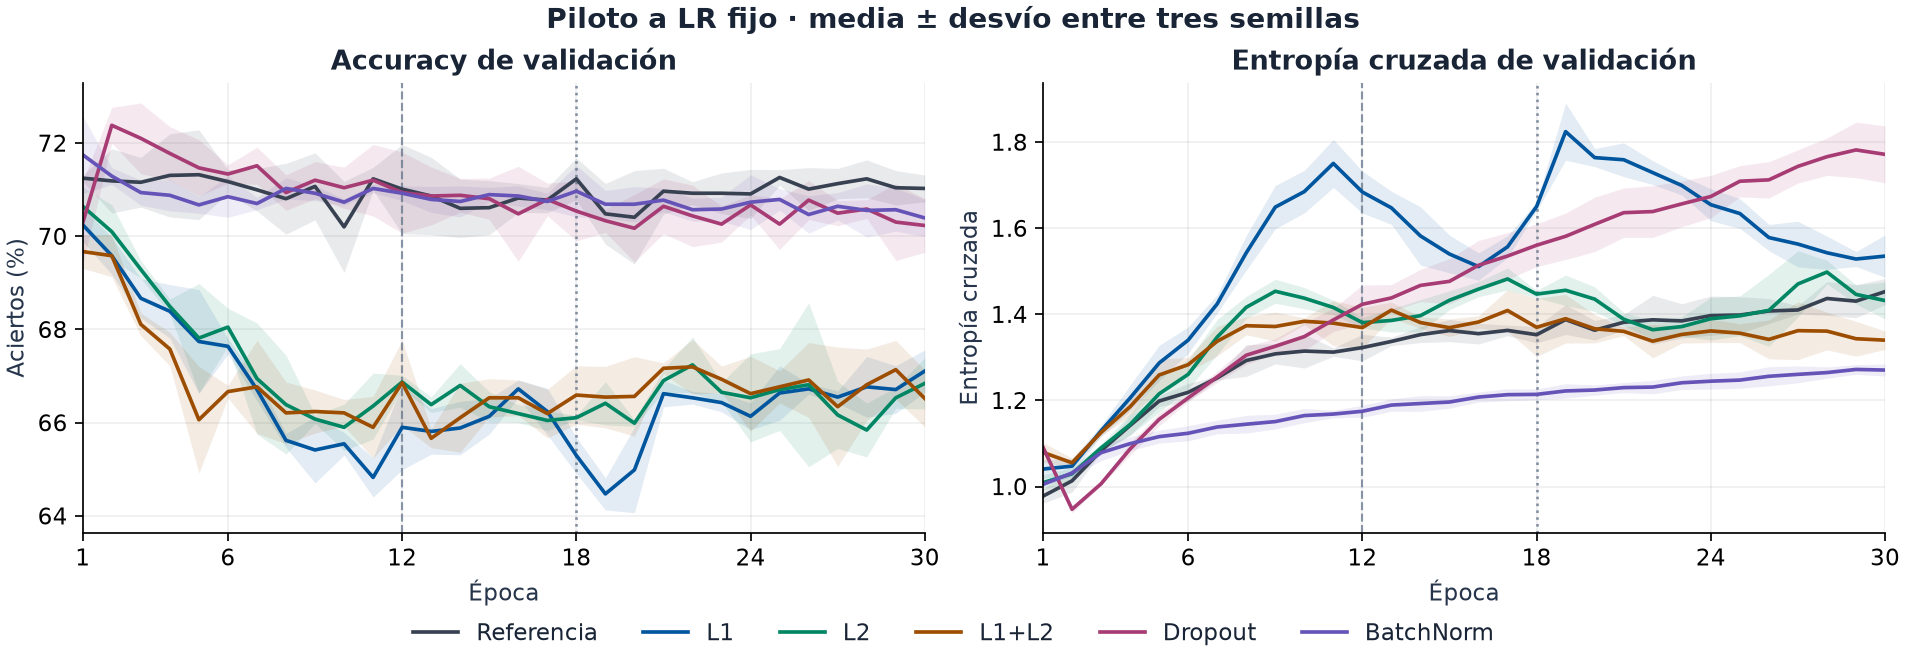

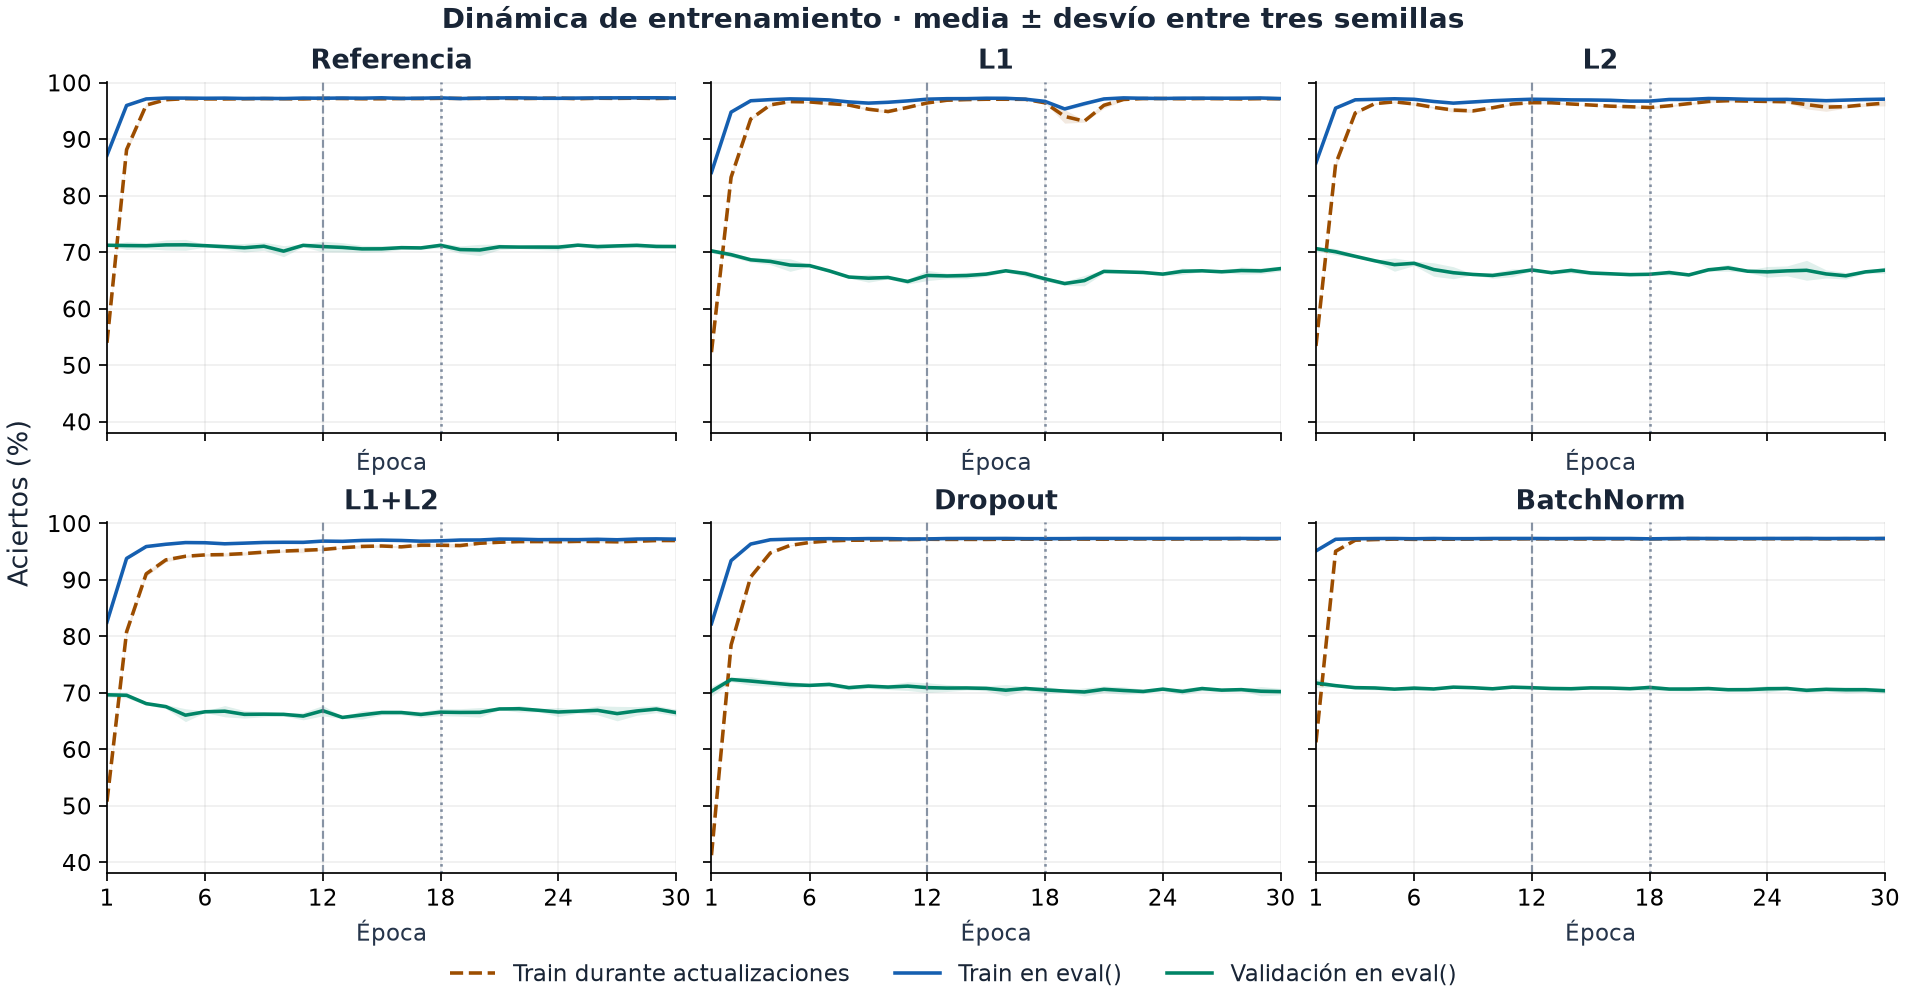

In [2]:
control = pd.DataFrame({
    "Modelo": resumen.family.map(nombres),
    "Época elegida": resumen.selected_epoch,
    "Val. elegida (%)": (100 * resumen.val_selected_mean).round(2),
    "Val. época 30 (%)": [
        f"{100 * mean:.2f} ± {100 * sd:.2f}"
        for mean, sd in zip(resumen.val_30_mean, resumen.val_30_sd)
    ],
    "Delta a 30 (pp)": resumen.paired_delta_30_pp_mean.round(2),
    "Tiempo mediano (s)": resumen.median_wall_s.round(1),
})
display(control.set_index("Modelo"))
display(Image(filename=str(salidas / "curvas_validacion.png")))
display(Image(filename=str(salidas / "curvas_entrenamiento.png")))

## Señal de mejoras tardías y tiempos

Para cada semilla se compara el máximo de la media móvil de tres épocas dentro de cada prefijo. Una familia activa la señal si al menos dos semillas ganan 0,5 puntos porcentuales o más entre los prefijos de 12 y 30. El CSV conserva también los máximos brutos y la época de cada máximo. [Prefijos por semilla](resultados/piloto/prefijos.csv)

,Ganancia mediana 30 vs. 12 (pp),Ganancia mediana 30 vs. 18 (pp),"Semillas con ganancia ≥ 0,5 pp",Señal
Modelo,,,,
Referencia,0.0,0.0,0,No
L1,0.0,0.0,0,No
L2,0.0,0.0,0,No
L1+L2,0.0,0.0,0,No
Dropout,0.0,0.0,0,No
BatchNorm,0.0,0.0,0,No


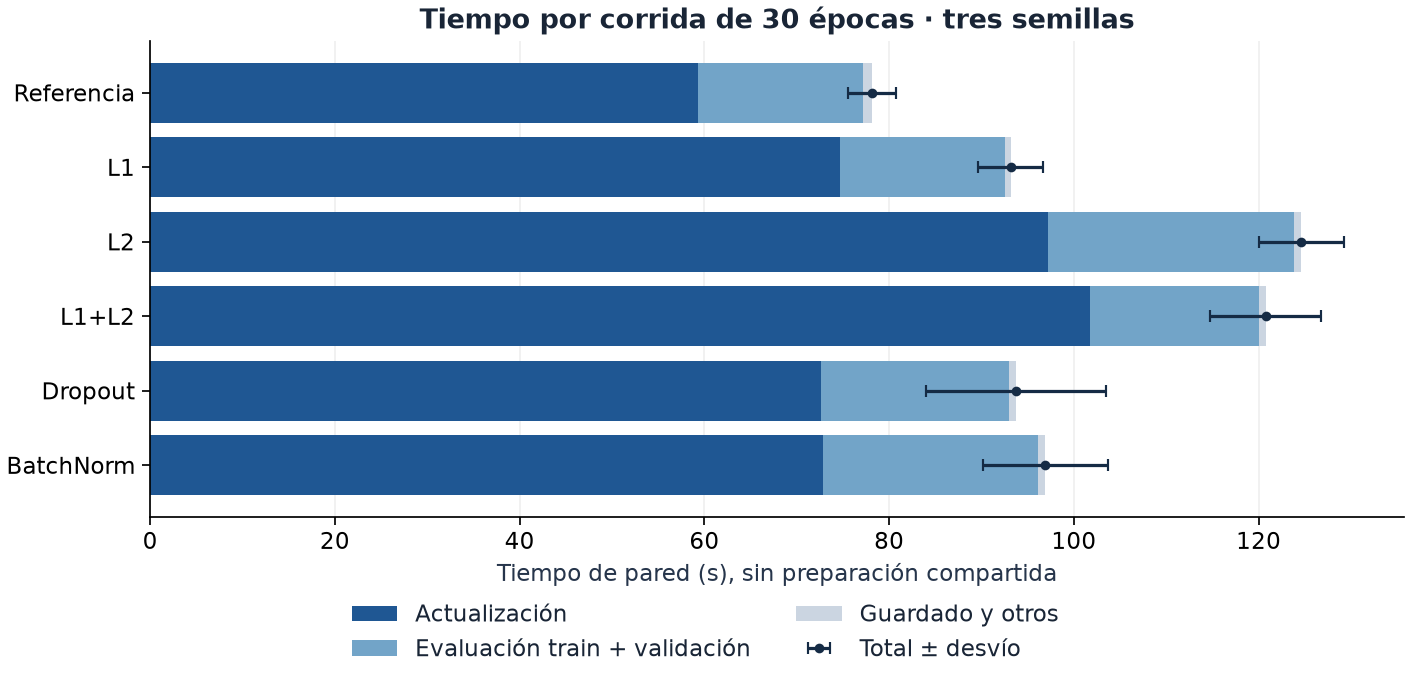

In [3]:
filtro = pd.DataFrame({
    "Modelo": resumen.family.map(nombres),
    "Ganancia mediana 30 vs. 12 (pp)": resumen.smooth_gain_30_vs_12_median_pp.round(2),
    "Ganancia mediana 30 vs. 18 (pp)": resumen.smooth_gain_30_vs_18_median_pp.round(2),
    "Semillas con ganancia ≥ 0,5 pp": resumen.late_seeds,
    "Señal": resumen.late_signal.map({True: "Sí", False: "No"}),
})
display(filtro.set_index("Modelo"))
display(Image(filename=str(salidas / "tiempos_piloto.png")))

### Lectura del piloto

Ninguna familia activó la señal de mejora tardía, por lo que se adoptó el horizonte base de 12 épocas para Optuna. A LR fijo, dropout alcanzó su pico de accuracy antes que la referencia, pero a la época 30 la referencia quedó arriba. Todas rondaron 97 % de accuracy en train al final. BatchNorm terminó con menor entropía cruzada de validación que la referencia (1,271 frente a 1,453), aunque acertó menos documentos. [Historial del piloto](resultados/piloto/epocas.csv) · [Implementación](codigo/piloto.py)

## Búsqueda base de Optuna

Se ejecutaron 72 intentos de 12 épocas, cuatro por combinación de familia y optimizador. Las seis anclas ocuparon un intento Adam por familia. Los otros 66 intentos se muestrearon con RandomSampler. Todos usaron la semilla de entrenamiento 42, el mismo orden de minibatches y la representación verificada del piloto.

El puntaje es la mejor media de accuracy de validación en tres épocas consecutivas. La época que figura en la tabla es el final de esa ventana. Las dos configuraciones únicas con mayor puntaje dentro de cada familia pasan a confirmación. El ancla completa el conjunto de candidatos de la familia y se reutiliza del piloto. El desglose conserva cada parámetro con precisión completa.

[Implementación](codigo/busqueda_optuna.py) · [72 intentos](resultados/optuna_base/trials.csv) · [Historial por época](resultados/optuna_base/epocas.csv) · [Cobertura observada](resultados/optuna_base/cobertura.json)

ID Optimizador         LR              Regularización  \
Familia    Orden                                                          
Referencia 1       4        Adam  0.0001836                           —   
           2       2        Adam  0.0002159                           —   
L1         1      16        Adam  0.0002354                λ₁=2.354e-07   
           2      17     RMSprop  0.0005573                λ₁=1.852e-06   
L2         1      28        Adam  0.0001685                λ₂=5.979e-06   
           2      30     RMSprop  0.0001541                 λ₂=7.55e-05   
L1+L2      1      40        Adam  0.0006479  λ₁=3.678e-06, λ₂=6.155e-06   
           2      44     RMSprop  0.0008013  λ₁=1.037e-05, λ₂=1.118e-06   
Dropout    1      54     RMSprop  0.0007635                    p=0.4912   
           2      56     RMSprop   0.001606                    p=0.3467   
BatchNorm  1      63        Adam   0.002246          momentum BN=0.1208   
           2      61        Adam      0.003             momentum BN=0.1   

                  Puntaje (%)  Fin de ventana Reusa piloto  
Familia    Orden                                            
Referencia 1            73.60              12           No  
           2            73.56              10           No  
L1         1            73.47              10           No  
           2            72.66               4           No  
L2         1            73.78              11           No  
           2            73.55              12           No  
L1+L2      1            72.85               5           No  
           2            71.17               4           No  
Dropout    1            73.28               8           No  
           2            73.15               4           No  
BatchNorm  1            71.69               3           No  
           2            71.17               6           Sí

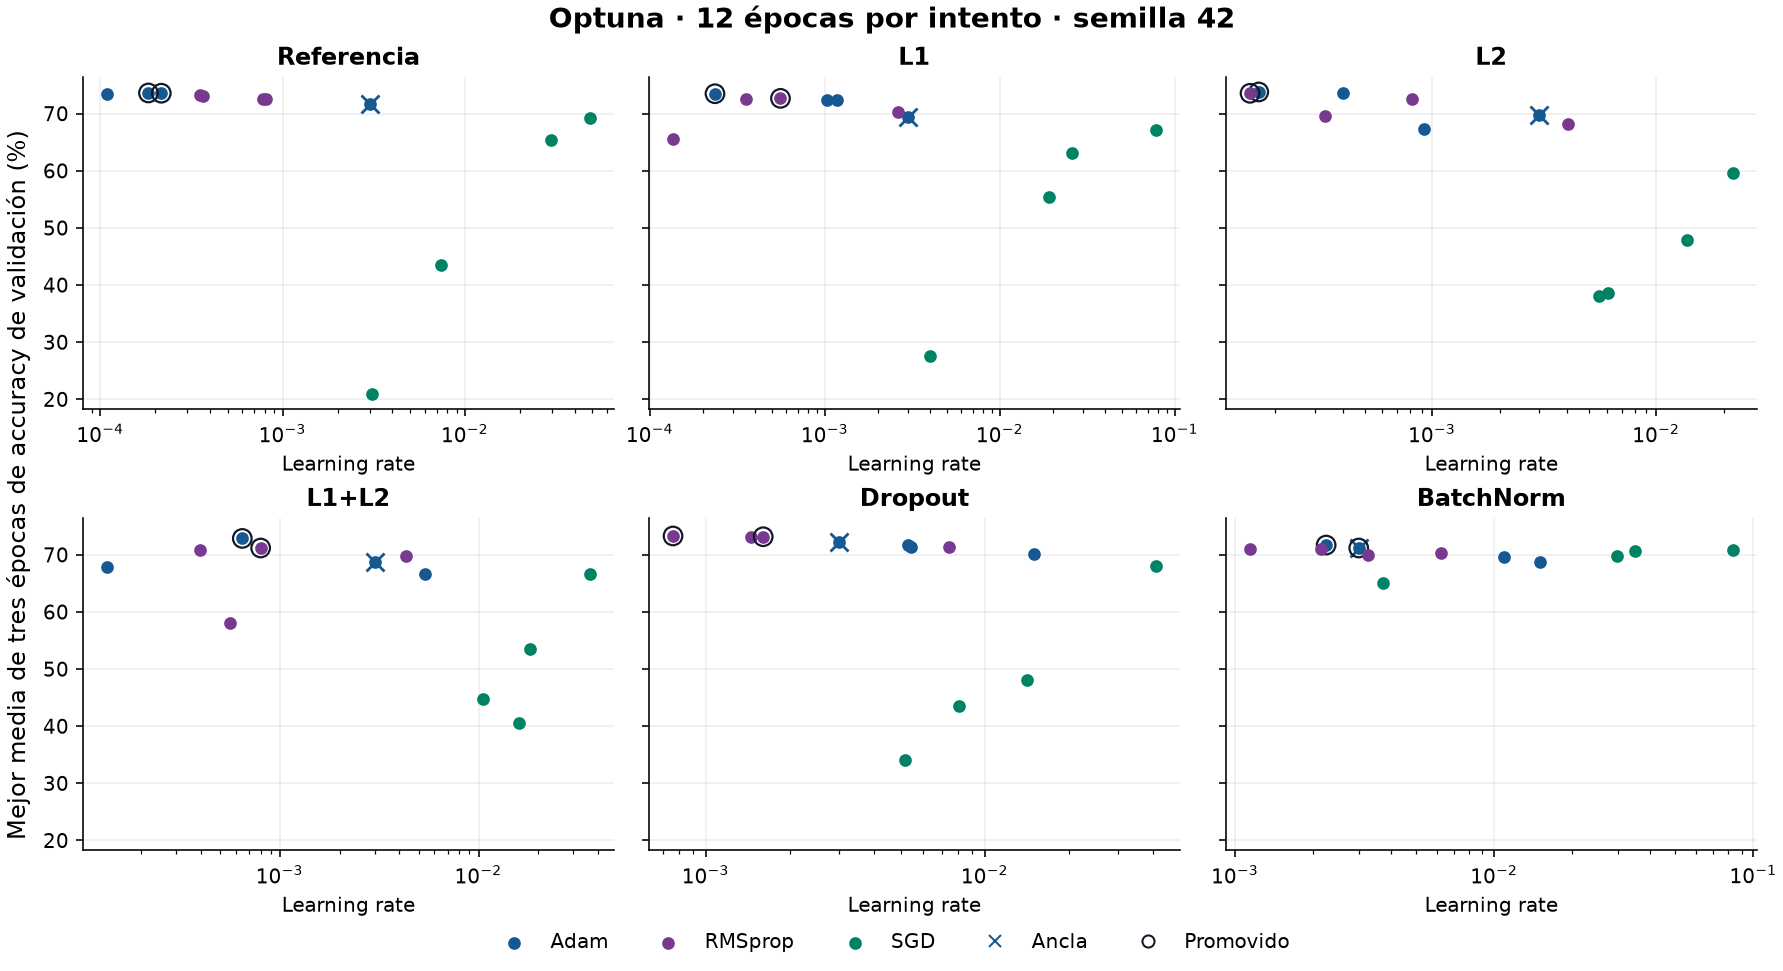

In [4]:
busqueda = Path("resultados/optuna_base")
promovidos = pd.read_csv(busqueda / "promovidos.csv")

def mostrar_regularizacion(fila):
    valores = []
    for columna, etiqueta in (
        ("l1", "λ₁"), ("l2", "λ₂"), ("dropout", "p"), ("bn_momentum", "momentum BN")
    ):
        valor = fila[columna]
        if pd.notna(valor) and valor > 0:
            valores.append(f"{etiqueta}={valor:.4g}")
    return ", ".join(valores) if valores else "—"

tabla_optuna = pd.DataFrame({
    "Familia": promovidos.family.map(nombres),
    "Orden": promovidos["rank"],
    "ID": promovidos.trial_id,
    "Optimizador": promovidos.optimizer,
    "LR": promovidos.lr.map(lambda value: f"{value:.4g}"),
    "Regularización": promovidos.apply(mostrar_regularizacion, axis=1),
    "Puntaje (%)": (100 * promovidos.smooth_acc).round(2),
    "Fin de ventana": promovidos.smooth_epoch,
    "Reusa piloto": promovidos.reuse_pilot.map({True: "Sí", False: "No"}),
})
display(tabla_optuna.set_index(["Familia", "Orden"]))
display(Image(filename=str(busqueda / "cobertura_lr.png")))

### Lectura de la búsqueda

El mejor puntaje de la muestra fue 73,78 % (L2, trial #28), a 0,18 pp del mejor caso sin regularización. Los dos promovidos de dropout usaron RMSprop. Hubo 24 intentos por optimizador. Los mejores puntajes de Adam, RMSprop y SGD fueron 73,78 %, 73,55 % y 70,75 %, respectivamente. Con cuatro intentos por combinación y una semilla, la cobertura permite filtrar configuraciones, con conclusiones limitadas a los valores ensayados y al horizonte de 12 épocas.

Un promovido de BN coincidió con su ancla. Eso dejó 17 configuraciones elegibles entre las 11 nuevas y las seis anclas. [Parámetros exactos de los promovidos](resultados/optuna_base/promovidos.csv)

## Confirmación y selección en validación

Se ajustaron las 11 configuraciones nuevas durante 30 épocas con las tres semillas y se reutilizaron las seis anclas. Para cada configuración se sumaron los aciertos de las tres semillas en cada época y se eligió el primer máximo. Ese mismo máximo decide la configuración de la familia. F1 macro se calculó al verificar los checkpoints y se informa como métrica secundaria. Los deltas emparejan semillas en la época elegida de cada configuración.

[Implementación](codigo/confirmacion.py) · [17 configuraciones](resultados/confirmacion/configuraciones.csv) · [Historial de las 51 corridas comparadas](resultados/confirmacion/epocas.csv)

,ID,Optimizador,LR,Época,Accuracy (%),F1 macro (%),Δ vs. referencia (pp),Δ vs. ancla (pp)
Familia,,,,,,,,
Referencia,4,Adam,0.0001836,12,73.57 ± 0.33,73.10 ± 0.45,0.000,2.254
L1,16,Adam,0.0002354,8,73.53 ± 0.48,72.91 ± 0.63,-0.044,3.285
L2,28,Adam,0.0001685,12,73.56 ± 0.24,72.98 ± 0.42,-0.015,2.916
L1+L2,40,Adam,0.0006479,5,72.57 ± 0.95,72.11 ± 1.12,-1.002,2.902
Dropout,54,RMSprop,0.0007635,6,73.56 ± 0.52,72.77 ± 0.54,-0.015,1.178
BatchNorm,63,Adam,0.002246,1,72.18 ± 0.40,71.75 ± 0.28,-1.399,0.427


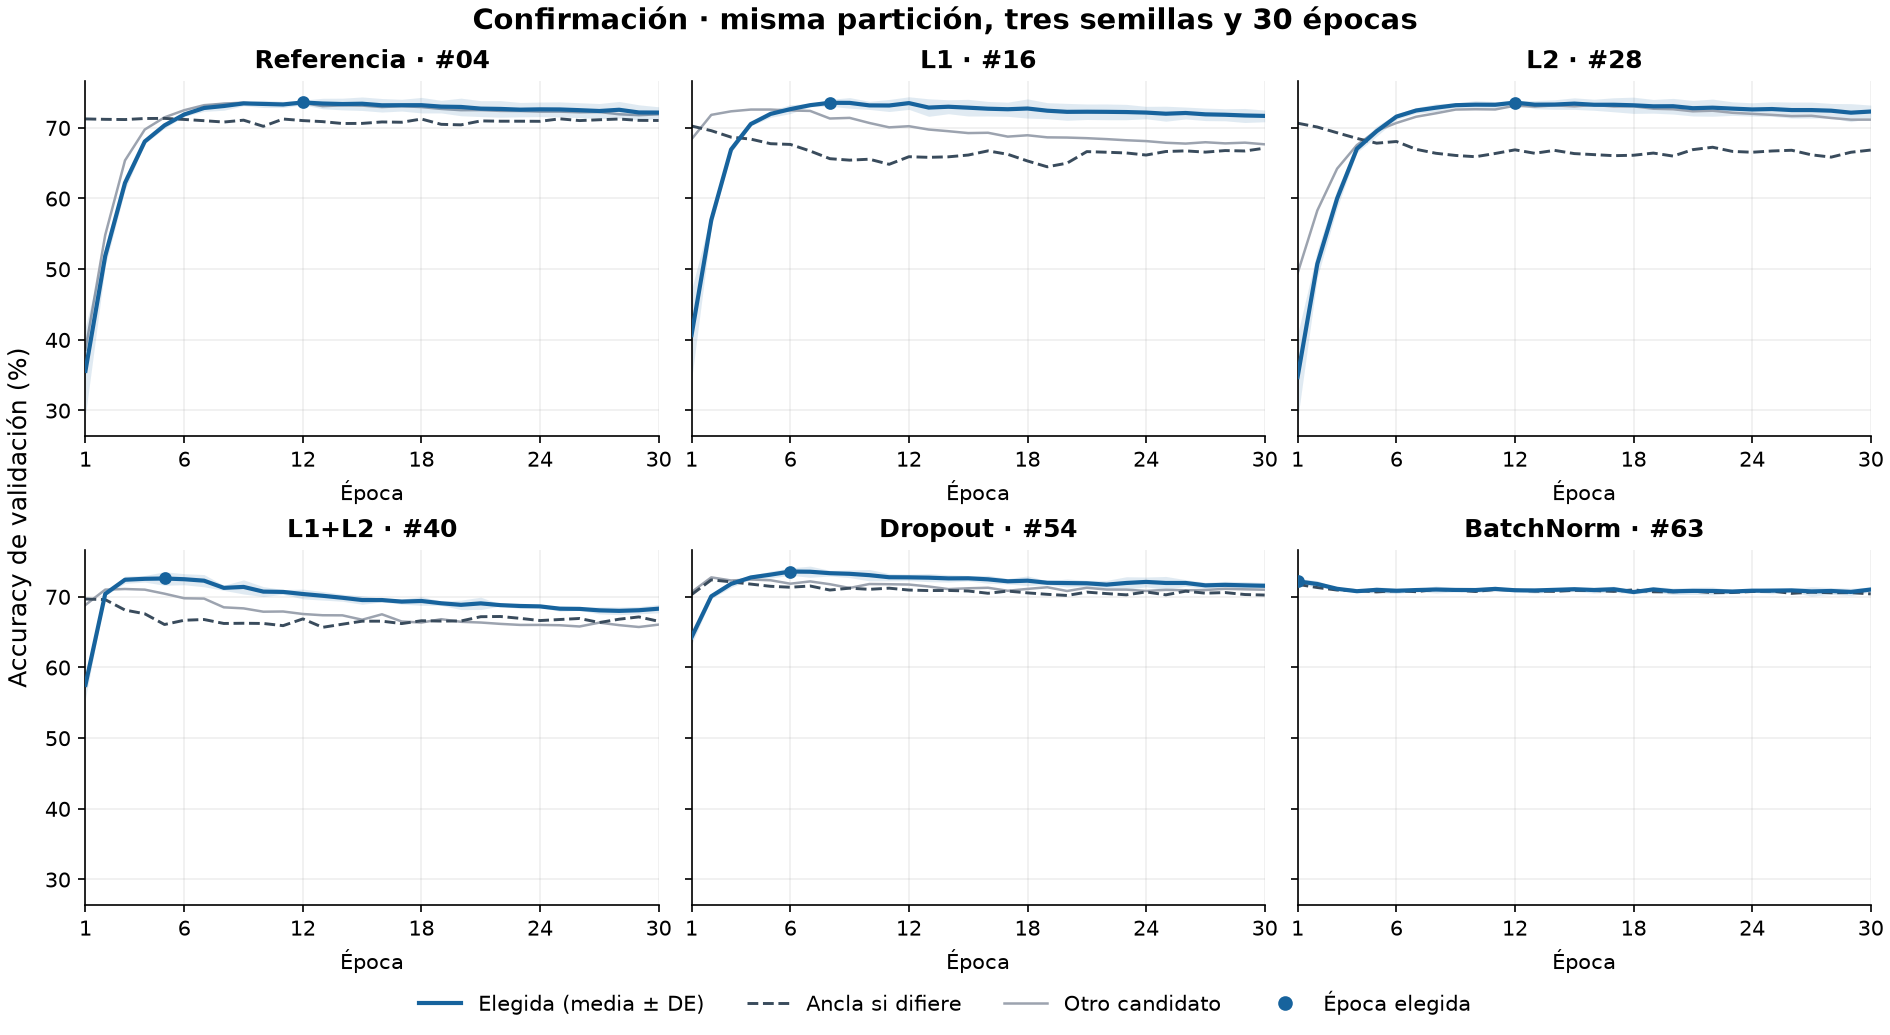

In [5]:
confirmacion = Path("resultados/confirmacion")
seleccion = pd.read_csv(confirmacion / "seleccion_resumen.csv")

def media_de(medias, desvios):
    return [f"{100 * media:.2f} ± {100 * de:.2f}" for media, de in zip(medias, desvios)]

tabla_confirma = pd.DataFrame({
    "Familia": seleccion.family.map(nombres),
    "ID": seleccion.trial_id,
    "Optimizador": seleccion.optimizer,
    "LR": seleccion.lr.map(lambda valor: f"{valor:.4g}"),
    "Época": seleccion.epoch,
    "Accuracy (%)": media_de(seleccion.val_acc_mean, seleccion.val_acc_sd),
    "F1 macro (%)": media_de(seleccion.val_f1_mean, seleccion.val_f1_sd),
    "Δ vs. referencia (pp)": seleccion.delta_vs_reference_pp.round(3),
    "Δ vs. ancla (pp)": seleccion.delta_vs_anchor_pp.round(3),
})
display(tabla_confirma.set_index("Familia"))
display(Image(filename=str(confirmacion / "curvas_confirmacion.png")))

### Lectura de la confirmación

Las seis configuraciones elegidas superaron a sus respectivas anclas en validación. Referencia, L1, L2 y dropout quedaron dentro de 0,05 pp. L2 y dropout quedaron a un acierto acumulado de la referencia, y L1 a tres, sobre 6.789 predicciones entre semillas. El candidato L2 #30 alcanzó su mejor media en la época 16. Su máximo quedó por debajo del #28 y las seis configuraciones elegidas alcanzaron su mejor media a más tardar en la época 12. Ambas observaciones corresponden a los candidatos confirmados. [Configuraciones y épocas de validación, con rango 1 para las elegidas](resultados/confirmacion/configuraciones.csv)

## Magnitud de los pesos

Se muestran los valores absolutos de los kernels de la primera capa. El bloque a 30 épocas con Adam y LR fijo permite comparar técnicas al mismo presupuesto. El bloque ajustado muestra también los pesos del checkpoint seleccionado, cuya época y LR pueden diferir entre familias. Cada estadístico se promedia sobre las tres semillas. El histograma usa los mismos intervalos para todas las curvas.

,Ancla P95 · e30,"Ancla ≤ 0,001 · e30 (%)",Ajustada P95 · elegida,Ajustada P95 · e30,"Ajustada ≤ 0,001 · e30 (%)"
Familia,,,,,
Referencia,0.115,1.255,0.050,0.061,2.310
L1,0.023,71.957,0.046,0.061,11.714
L2,0.060,18.308,0.047,0.057,3.530
L1+L2,0.028,72.951,0.048,0.047,61.284
Dropout,0.146,1.070,0.060,0.094,1.620
BatchNorm,0.067,2.466,0.042,0.054,3.001


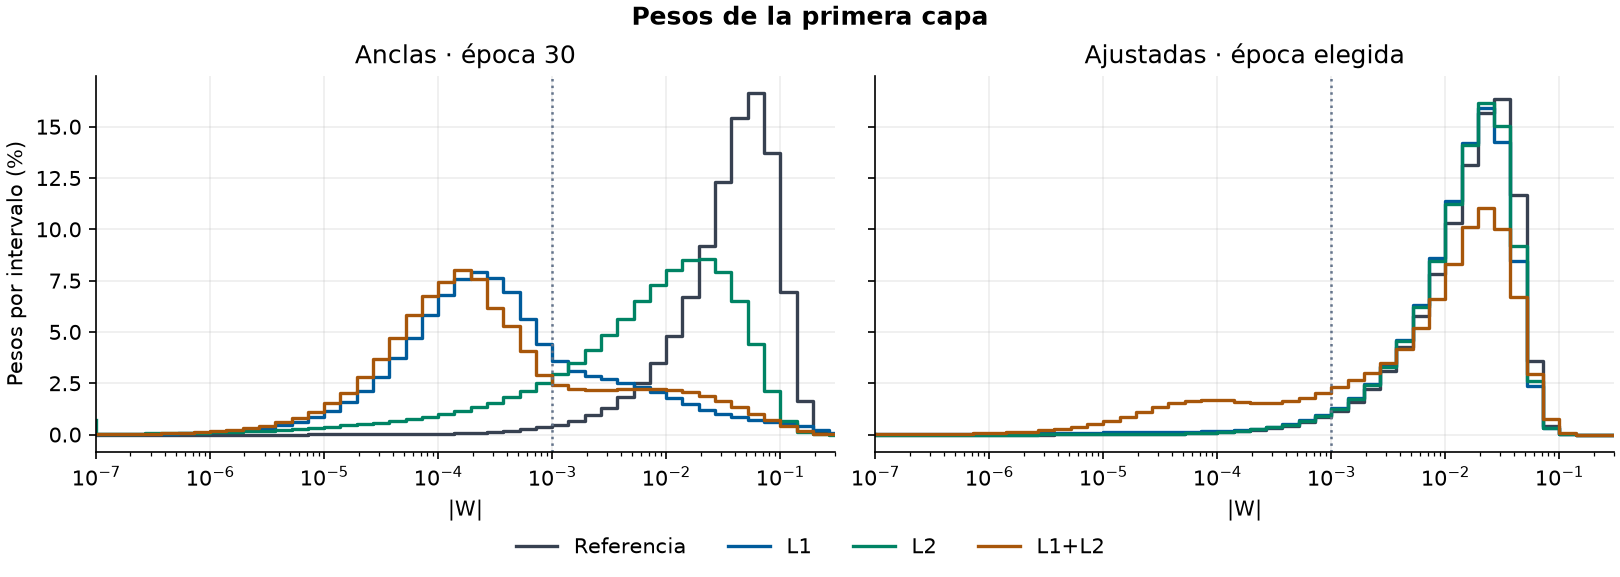

In [6]:
perfiles = {"Ancla": {}, "Ajustada": {}}
for caso in seleccion.itertuples(index=False):
    carpetas = {
        "Ancla": salidas / "corridas" / caso.family,
        "Ajustada": confirmacion / "corridas" / f"trial_{caso.trial_id:03d}",
    }
    for tipo, carpeta in carpetas.items():
        perfiles[tipo][caso.family] = [
            leer_json(carpeta / str(s) / "historial.json") for s in semillas
        ]

def promedio_peso(tipo, familia, instante, campo):
    return np.mean([registro[instante][0][campo] for registro in perfiles[tipo][familia]])

tabla_pesos = pd.DataFrame(
    [{
        "Familia": etiqueta,
        "Ancla P95 · e30": promedio_peso("Ancla", familia, "last_weights", "p95"),
        "Ancla ≤ 0,001 · e30 (%)": 100 * promedio_peso("Ancla", familia, "last_weights", "near_zero_fraction"),
        "Ajustada P95 · elegida": promedio_peso("Ajustada", familia, "selected_weights", "p95"),
        "Ajustada P95 · e30": promedio_peso("Ajustada", familia, "last_weights", "p95"),
        "Ajustada ≤ 0,001 · e30 (%)": 100 * promedio_peso("Ajustada", familia, "last_weights", "near_zero_fraction"),
    } for familia, etiqueta in nombres.items()]
).set_index("Familia")
display(tabla_pesos.round(3))

bordes = np.array(leer_json(salidas / "protocolo.json")["histogram_bins"])
colores = {"referencia": "#374151", "l1": "#005b9b", "l2": "#008364", "l1_l2": "#a7560a"}
fig, ejes = plt.subplots(1, 2, figsize=(10.8, 3.85), sharey=True, layout="constrained")
for eje, (tipo, instante, titulo) in zip(ejes, (
    ("Ancla", "last_weights", "Anclas · época 30"),
    ("Ajustada", "selected_weights", "Ajustadas · época elegida"),
)):
    for familia, color in colores.items():
        fracciones = []
        for registro in perfiles[tipo][familia]:
            capa = registro[instante][0]
            fracciones.append(np.array(capa["histogram"]) / capa["n"])
        eje.step(bordes[1:], 100 * np.mean(fracciones, axis=0), where="pre", lw=1.6,
                 label=nombres[familia], color=color)
    eje.axvline(1e-3, color="#64748b", ls=":", lw=1.2)
    eje.set(xscale="log", xlim=(1e-7, 0.3), xlabel="|W|", title=titulo)
    eje.grid(alpha=0.22)
    eje.spines[["top", "right"]].set_visible(False)
ejes[0].set_ylabel("Pesos por intervalo (%)")
fig.legend(*ejes[0].get_legend_handles_labels(), loc="outside lower center", ncol=4, frameon=False)
fig.suptitle("Pesos de la primera capa", weight="bold")
visual = BytesIO()
fig.savefig(visual, format="png", dpi=150, facecolor="white")
plt.close(fig)
display(Image(data=visual.getvalue()))

En el bloque controlado, L1 y L1+L2 dejaron alrededor de 72 % y 73 % de los pesos de la primera capa con |W| ≤ 0,001 a la época 30, con una proporción despreciable de ceros exactos. L2 redujo el P95 de 0,115 a 0,060. Son patrones compatibles con la presión de L1 hacia pesos pequeños y con la penalización cuadrática de la cola en L2. En el L1 ajustado se eligieron un λ más bajo y la época 8, con una concentración cercana a cero menos marcada. En BN, la escala efectiva en evaluación incluye γ/√(var acumulada + ε). Por eso el tamaño del kernel por sí solo no caracteriza la escala del bloque. [Estadísticas por capa del piloto](resultados/piloto/pesos.csv)

## Ruido, LR y tiempos

La rugosidad es el RMS de las diferencias respecto de una media móvil centrada de cinco épocas, entre las épocas 13 y 28. Se calcula por corrida y se promedia entre semillas. La tabla expresa la rugosidad de accuracy en puntos porcentuales. El tiempo de pared de una corrida incluye actualización, evaluación y guardado. Los tiempos hasta 70 % de accuracy de validación y hasta la época elegida acumulan actualización y evaluación. El 70 % es un umbral descriptivo.

In [7]:
def rugosidad(historial, clave):
    valores = np.array([fila[clave] for fila in historial]) * 100
    centrada = np.convolve(valores, np.ones(5) / 5, mode="valid")
    return np.sqrt(np.mean((valores[12:28] - centrada[10:26]) ** 2))

ruido = []
tiempos = []
for caso in seleccion.itertuples(index=False):
    familia = caso.family
    fila_ruido = {"Familia": nombres[familia]}
    for tipo, registro_familiar in perfiles.items():
        historiales = [registro["epochs"] for registro in registro_familiar[familia]]
        for etiqueta, clave in (("online", "train_online_acc"), ("eval", "train_eval_acc"), ("val", "val_acc")):
            fila_ruido[f"{tipo} · {etiqueta}"] = np.mean([rugosidad(h, clave) for h in historiales])
    ruido.append(fila_ruido)

    originales = perfiles["Ancla"][familia]
    ajustadas = perfiles["Ajustada"][familia]
    hasta_umbral, hasta_elegida = [], []
    for registro in ajustadas:
        historial = registro["epochs"]
        segundos = np.cumsum([fila["update_s"] + fila["eval_s"] for fila in historial])
        alcanzado = next((i for i, fila in enumerate(historial) if fila["val_acc"] >= 0.70), None)
        if alcanzado is not None:
            hasta_umbral.append(segundos[alcanzado])
        hasta_elegida.append(segundos[caso.epoch - 1])
    tiempo_umbral = f"{np.median(hasta_umbral):.1f} ({len(hasta_umbral)}/3)" if hasta_umbral else "— (0/3)"
    tiempos.append({
        "Familia": nombres[familia],
        "Pared 30 e · ancla (s)": np.median([registro["wall_s"] for registro in originales]),
        "Pared 30 e · ajustada (s)": np.median([registro["wall_s"] for registro in ajustadas]),
        "Hasta 70 % · ajustada (s, semillas)": tiempo_umbral,
        "Hasta época elegida · ajustada (s)": np.median(hasta_elegida),
    })
display(pd.DataFrame(ruido).set_index("Familia").round(3))
display(pd.DataFrame(tiempos).set_index("Familia").round(1))

,Ancla · online,Ancla · eval,Ancla · val,Ajustada · online,Ajustada · eval,Ajustada · val
Familia,,,,,,
Referencia,0.039,0.057,0.303,0.072,0.067,0.146
L1,0.784,0.360,0.518,0.057,0.040,0.162
L2,0.214,0.103,0.438,0.084,0.071,0.127
L1+L2,0.137,0.087,0.399,0.026,0.033,0.236
Dropout,0.035,0.019,0.300,0.096,0.032,0.184
BatchNorm,0.019,0.021,0.166,0.024,0.010,0.167


,Pared 30 e · ancla (s),Pared 30 e · ajustada (s),"Hasta 70 % · ajustada (s, semillas)",Hasta época elegida · ajustada (s)
Familia,,,,
Referencia,77.5,72.0,12.5 (3/3),28.1
L1,94.8,94.1,11.4 (3/3),22.9
L2,127.0,97.4,17.9 (3/3),38.3
L1+L2,120.9,113.2,7.4 (3/3),19.3
Dropout,89.7,74.5,6.8 (3/3),14.1
BatchNorm,93.5,75.6,2.8 (3/3),2.8


- **Ruido.** A LR fijo, BN tuvo una rugosidad de validación de 0,17 pp y la referencia de 0,30 pp. En dropout ajustado, la rugosidad del train online fue de 0,096 pp y la del train en modo de evaluación de 0,032 pp. La brecha entre esas mediciones en la primera época promedió 40,1 pp, frente a 21,9 pp de la referencia ajustada. El enmascarado durante el entrenamiento es una explicación parcial. El registro online también promedia predicciones con pesos que cambian dentro de la época. En los 15 minibatches iniciales observados del ancla BN ningún canal quedó por debajo de ε.
- **LR.** Todos los LR elegidos quedaron por debajo de 0,003. Cinco quedaron entre 1,69×10⁻⁴ y 7,63×10⁻⁴. En la referencia, donde se mantuvo Adam y no hay penalización explícita, bajar el LR de 0,003 a 1,84×10⁻⁴ coincidió con tardar más en llegar a 70 % y con reducir la rugosidad de validación de 0,30 a 0,15 pp. En las otras familias cambiaron también la fuerza de regularización o el optimizador según el caso.
- **Tiempos.** Las corridas sumaron 30 min 22 s en piloto, 43 min 56 s en Optuna y 48 min 29 s en confirmación. La preparación compartida tomó 31, 36 y 34 s, respectivamente. Las medianas reportan el costo observado en CPU e incluyen la variación del equipo durante las corridas. Una época elegida temprana reduce el tiempo hasta ese checkpoint, aunque cada confirmación haya ejecutado el mismo presupuesto. En el piloto, simular early stopping con seis épocas de paciencia habría detenido las 18 corridas. En una habría omitido una mejora posterior. [Tiempos por corrida de confirmación](resultados/confirmacion/corridas.csv)

## Evaluación final en test

Se usaron los 18 checkpoints fijados en validación y el vocabulario e IDF guardados de train interno. Cada checkpoint se evaluó sobre los mismos 7.532 documentos del test oficial, con dropout desactivado y las estadísticas acumuladas de BN. Accuracy y F1 macro se muestran como media ± desvío estándar muestral de tres semillas. Los deltas son las diferencias emparejadas con la referencia de la misma semilla, en puntos porcentuales.

[Resultados por semilla](resultados/test_final/test_por_semilla.csv) · [Resumen de test](resultados/test_final/test_resumen.csv) · [Implementación del test](codigo/test_final.py)

In [8]:
test_final = resultados / "test_final"
resumen_test = pd.read_csv(test_final / "test_resumen.csv")
assert resumen_test[["family", "trial_id", "epoch"]].equals(seleccion[["family", "trial_id", "epoch"]])

def diferencia_de(medias, desvios):
    return [f"{media:+.3f} ± {de:.3f}" for media, de in zip(medias, desvios)]

tabla_test = pd.DataFrame({
    "Familia": resumen_test.family.map(nombres),
    "Accuracy (%)": media_de(resumen_test.accuracy_mean, resumen_test.accuracy_sd),
    "F1 macro (%)": media_de(resumen_test.f1_macro_mean, resumen_test.f1_macro_sd),
    "Δ accuracy (pp)": diferencia_de(resumen_test.delta_accuracy_pp_mean, resumen_test.delta_accuracy_pp_sd),
    "Δ F1 macro (pp)": diferencia_de(resumen_test.delta_f1_pp_mean, resumen_test.delta_f1_pp_sd),
})
display(tabla_test.set_index("Familia"))

,Accuracy (%),F1 macro (%),Δ accuracy (pp),Δ F1 macro (pp)
Familia,,,,
Referencia,66.53 ± 0.03,65.53 ± 0.10,+0.000 ± 0.000,+0.000 ± 0.000
L1,66.54 ± 0.07,65.47 ± 0.11,+0.004 ± 0.054,-0.056 ± 0.030
L2,66.53 ± 0.05,65.47 ± 0.14,+0.000 ± 0.035,-0.061 ± 0.061
L1+L2,65.55 ± 0.19,64.78 ± 0.21,-0.987 ± 0.162,-0.744 ± 0.188
Dropout,66.72 ± 0.13,65.48 ± 0.15,+0.181 ± 0.103,-0.052 ± 0.055
BatchNorm,64.94 ± 0.47,63.88 ± 0.49,-1.598 ± 0.471,-1.648 ± 0.459


Dropout acertó 20, 5 y 16 documentos más que la referencia, respectivamente, en las semillas 101, 202 y 303. Su ganancia media en accuracy fue de 0,181 pp. La referencia obtuvo el mayor F1 macro medio. Como F1 macro da el mismo peso a las 20 clases, una mejora en el total de aciertos puede coexistir con un menor balance medio entre precisión y recall. L1 y L2 quedaron prácticamente empatados con la referencia en accuracy. La comparación ajustada mide configuraciones completas con sus respectivos LR, optimizadores y épocas. La dispersión describe sensibilidad a las semillas sobre un split fijo. El split oficial ya se había usado en el TP2 y las configuraciones y épocas de este TP se fijaron en validación.

## Diagnósticos complementarios en validación

Los cinco casos se definieron en el plan y se ejecutaron después del test principal. Se ajustaron exclusivamente con train interno y se evaluaron **solo en validación**. Estos resultados son descriptivos y la selección principal ya estaba fijada. Se reutilizaron las anclas de dropout (p = 0,35) y de la MLP sin regularización como controles. Cada caso usó Adam, LR inicial 0,003, las semillas 101, 202 y 303 y 30 épocas, para un total de 15 corridas y 450 épocas. Las corridas sumaron 22 min 33 s de pared.

En meseta, el LR se redujo a la mitad cuando pasaron cuatro épocas consecutivas sin mejora de accuracy de validación, con piso de 0,0001. Max-norm proyectó las filas de los kernels ocultos cuya norma L2 excedía 5 después de cada actualización. El escalador de TF‑IDF se ajustó solo con train interno. En el caso Xavier se duplicó el radio de la primera capa a partir de los mismos pesos iniciales de cada semilla.

La tabla usa media ± desvío muestral. Los deltas a la época 30 emparejan cada variante con su ancla por semilla. [Implementación](codigo/diagnosticos.py) · [Resumen](resultados/diagnosticos/resumen.csv) · [Historial por semilla](resultados/diagnosticos/corridas.csv)

,Ancla,Accuracy de validación a e30 (%),Δ a e30 (pp),Tiempo mediano 30 e (s)
Variante,,,,
Dropout + meseta,Dropout,71.53 ± 0.38,+1.296 ± 0.251,98.5
Dropout + max-norm,Dropout,68.08 ± 0.55,-2.151 ± 1.062,94.8
Dropout + ambos,Dropout,71.31 ± 0.40,+1.075 ± 0.227,93.9
Xavier R₁ × 2,Referencia,70.78 ± 0.24,-0.250 ± 0.155,86.4
TF‑IDF estandarizado,Referencia,66.58 ± 1.49,-4.448 ± 1.572,78.2


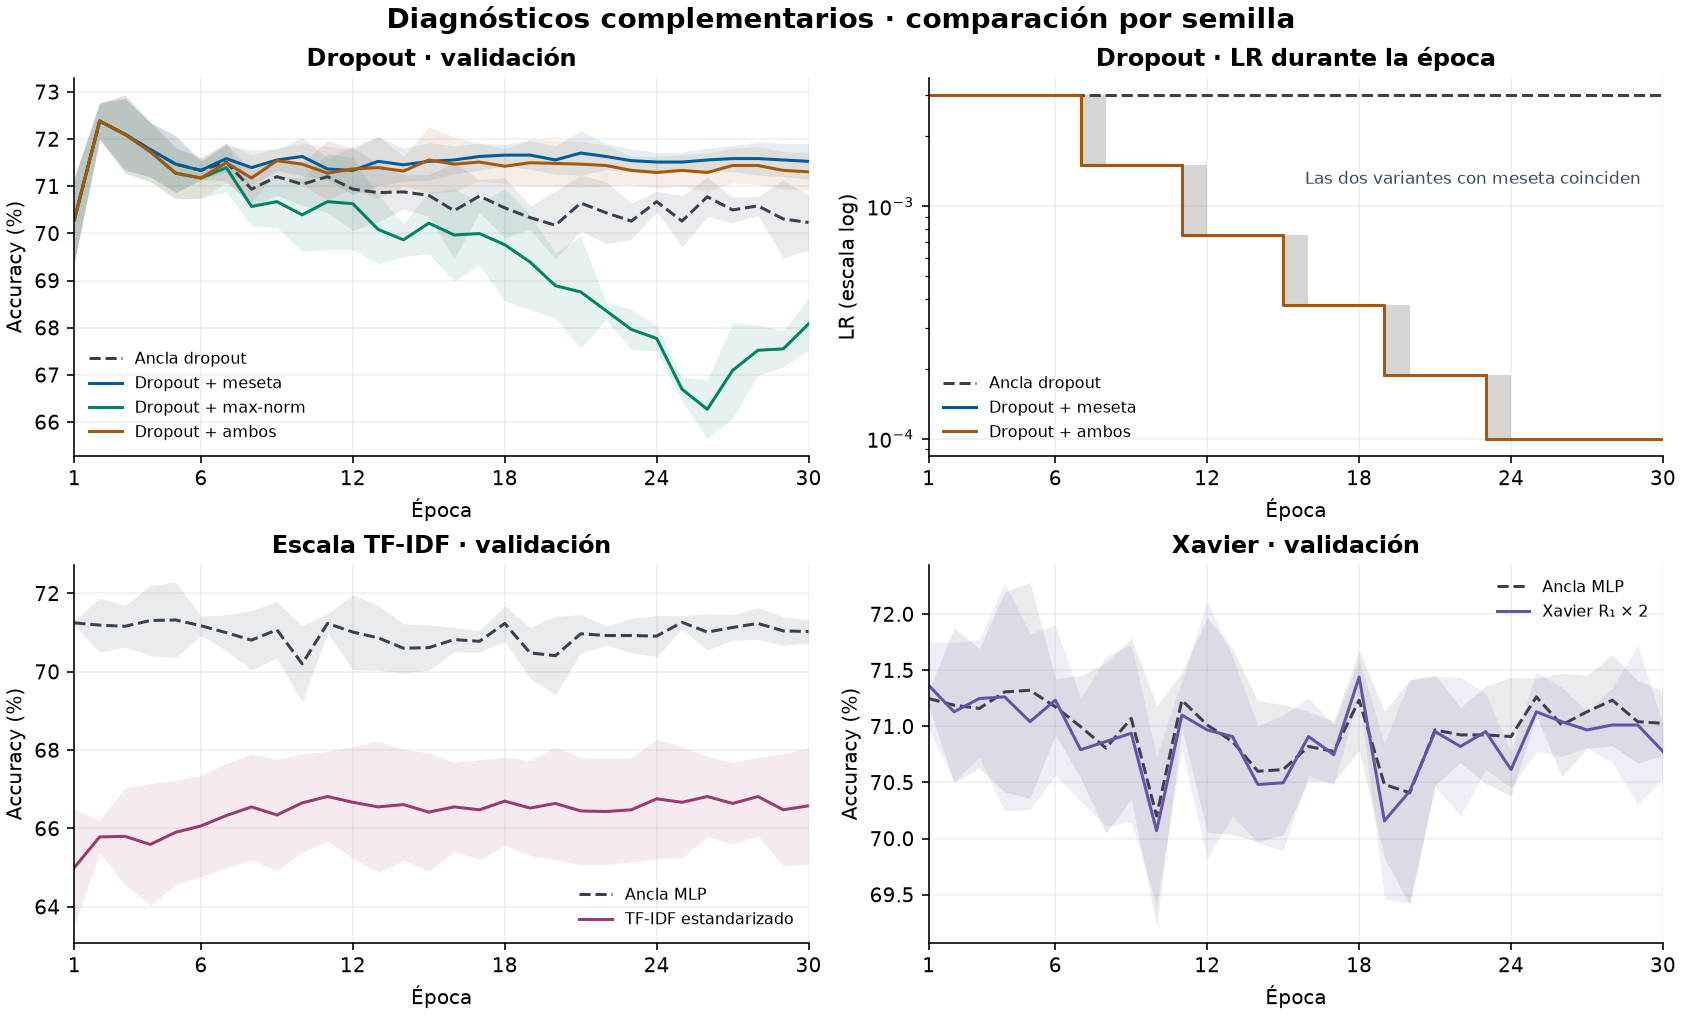

In [9]:
diagnosticos = resultados / "diagnosticos"
resumen_diag = pd.read_csv(diagnosticos / "resumen.csv")
nombres_diag = {
    "dropout_plateau": "Dropout + meseta",
    "dropout_max_norm": "Dropout + max-norm",
    "dropout_plateau_max_norm": "Dropout + ambos",
    "xavier_r_x2": "Xavier R₁ × 2",
    "tfidf_estandarizado": "TF‑IDF estandarizado",
}
tabla_diagnosticos = pd.DataFrame({
    "Variante": resumen_diag.case.map(nombres_diag),
    "Ancla": resumen_diag.anchor.map(nombres),
    "Accuracy de validación a e30 (%)": media_de(resumen_diag.val_e30_mean, resumen_diag.val_e30_sd),
    "Δ a e30 (pp)": diferencia_de(resumen_diag.delta_e30_pp_mean, resumen_diag.delta_e30_pp_sd),
    "Tiempo mediano 30 e (s)": resumen_diag.median_wall_s.round(1),
})
display(tabla_diagnosticos.set_index("Variante"))
display(Image(filename=str(diagnosticos / "curvas_diagnosticos.png")))

### Lectura de los diagnósticos

- **Dropout.** La meseta mantuvo el pico del ancla en 72,38 % (época 2), mejoró la accuracy a la época 30 en 1,30 pp y redujo la rugosidad de validación de 0,30 a 0,095 pp. Las dos variantes con meseta siguieron el mismo LR por semilla, con cinco reducciones en cada corrida. Con max-norm solo, la accuracy cayó 2,15 pp al final. La proyección actuó en el 89,1 % de las filas examinadas a lo largo de las actualizaciones de la primera capa. Con ambos cambios, el delta final fue de +1,08 pp.
- **TF‑IDF.** A LR fijo, la estandarización redujo la accuracy final en 4,45 pp. Ninguna semilla alcanzó el umbral de 70 %. La mediana del factor inverso del desvío fue 287,3 para términos presentes en 2–5 documentos y 56,7 para términos presentes en al menos 100. Esto describe el cambio de escala de entrada del ensayo.
- **Xavier.** Duplicar el radio duplicó el RMS inicial de las preactivaciones en el mismo minibatch. La accuracy de validación varió +0,12 pp en la primera época y −0,25 pp al final, frente a la referencia. El cambio de escala inicial tuvo un efecto pequeño en accuracy bajo este protocolo.

[Historial por época](resultados/diagnosticos/epocas.csv) · [Análisis y verificación de los diagnósticos](resultados/diagnosticos/analisis_diagnosticos.json) · [Early stopping retrospectivo del piloto](resultados/piloto/corridas.csv)

## Conclusión

En el piloto a LR fijo, al cabo de 30 épocas, L1 concentró más pesos de la primera capa cerca de cero (|W| ≤ 0,001) y L2 redujo el percentil 95 de |W| en esa capa, frente a la referencia. En test, el dropout ajustado superó a la referencia por 0,18 puntos porcentuales de accuracy media. La referencia obtuvo el mayor F1 macro medio. Se usaron las semillas emparejadas 101, 202 y 303 sobre una partición fija.